# 2. Deteksi & Inferensi Gambar Uji (`Class 0`, `Class 1`, atau `undefined`)

Notebook ini digunakan untuk menginput gambar dan mendeteksi secara langsung apakah gambar tersebut termasuk:
- **`Class 0` : Betina (`hen`)** (jika *Confidence* $\ge 80\%$) $\rightarrow$ Aktuasi Servo ESP32 ke **`0 Derajat`**
- **`Class 1` : Jantan (`cock`)** (jika *Confidence* $\ge 80\%$) $\rightarrow$ Aktuasi Servo ESP32 ke **`180 Derajat`**
- **`undefined` : Gambar Kosong / Bukan Ayam** (jika *Confidence* $< 80\%$ atau frame kosong/polos) $\rightarrow$ Aktuasi Servo ESP32 tetap di **`90 Derajat (Standby)`**

Inferensi dilakukan langsung menggunakan model kuantisasi **`../model/model_int8.tflite`**.

## Langkah 1: Import Library, Konfigurasi Threshold, & Load Model `model_int8.tflite`

### Konfigurasi Nilai Threshold:
1. **`CONFIDENCE_THRESHOLD = 0.80` (80%)**:
   Jika probabilitas tertinggi dari model di bawah **80%**, maka hasil klasifikasi otomatis ditetapkan menjadi **`undefined`**.
2. **`BLANK_STD_THRESHOLD = 12.0`**:
   Mendeteksi gambar kosong/polos (seperti kertas kosong, meja/tembok polos, atau lensa tertutup) berdasarkan standar deviasi kontras piksel. Jika di bawah nilai ini, hasil klasifikasi langsung menjadi **`undefined`**.

In [1]:
import os
import time
import pathlib
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf

# Path menuju model_int8.tflite hasil training
TFLITE_MODEL_PATH = pathlib.Path("../model/model_int8.tflite")

# --- KONFIGURASI THRESHOLD DETEKSI UNDEFINED ---
CONFIDENCE_THRESHOLD = 0.80   # Minimal confidence 80% (0.80) agar diakui sebagai Class 0 atau Class 1
BLANK_STD_THRESHOLD = 12.0    # Minimal variasi piksel (0-255); di bawah ini dianggap frame kosong (undefined)

CLASS_MAP = {
    0: {"code": "0", "name": "Betina (hen)", "servo_angle": 0, "color": "#2ca02c"},
    1: {"code": "1", "name": "Jantan (cock)", "servo_angle": 180, "color": "#d62728"},
    "undefined": {"code": "undefined", "name": "undefined (Bukan Ayam / Kosong)", "servo_angle": 90, "color": "#7f7f7f"},
}

if not TFLITE_MODEL_PATH.exists():
    raise FileNotFoundError(
        f"File {TFLITE_MODEL_PATH} belum ditemukan! "
        "Jalankan terlebih dahulu notebook '1_training_dan_evaluasi_mobilenetv2.ipynb'."
    )

# Inisialisasi TFLite Interpreter
interpreter = tf.lite.Interpreter(model_path=str(TFLITE_MODEL_PATH))
interpreter.allocate_tensors()

input_details = interpreter.get_input_details()[0]
output_details = interpreter.get_output_details()[0]

IMG_HEIGHT, IMG_WIDTH = input_details["shape"][1], input_details["shape"][2]
in_scale, in_zero_point = input_details["quantization"]
out_scale, out_zero_point = output_details["quantization"]

print(f"Model berhasil dimuat : {TFLITE_MODEL_PATH.resolve()}")
print(f"Resolusi Input Model  : {IMG_WIDTH}x{IMG_HEIGHT} RGB ({input_details['dtype'].__name__})")
print(f"Confidence Threshold  : {CONFIDENCE_THRESHOLD * 100:.0f}% (Di bawah ini -> 'undefined')")
print(f"Blank Frame Threshold : std < {BLANK_STD_THRESHOLD} (Frame kosong/polos -> 'undefined')")

2026-10-06 15:15:48.513349: I tensorflow/core/util/port.cc:113] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-10-06 15:15:48.516234: I external/local_tsl/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2026-10-06 15:15:48.548681: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-10-06 15:15:48.548712: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-10-06 15:15:48.551363: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to

Model berhasil dimuat : /home/nexus_is/PP2/model/model_int8.tflite
Resolusi Input Model  : 160x160 RGB (int8)
Confidence Threshold  : 80% (Di bawah ini -> 'undefined')
Blank Frame Threshold : std < 12.0 (Frame kosong/polos -> 'undefined')


INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


## Langkah 2: Fungsi Deteksi Gambar (`detect_chicken_sex`)

Fungsi ini menerima path gambar (atau objek `PIL.Image`), melakukan *preprocessing* + kuantisasi `INT8`, menjalankan inferensi, lalu mengembalikan:
- **`Class 0`** jika objek terdeteksi Betina dengan *confidence* $\ge 80\%$
- **`Class 1`** jika objek terdeteksi Jantan dengan *confidence* $\ge 80\%$
- **`undefined`** jika gambar kosong/polos atau *confidence* $< 80\%$

In [2]:
def detect_chicken_sex(
    image_input,
    threshold=CONFIDENCE_THRESHOLD,
    blank_std_threshold=BLANK_STD_THRESHOLD,
    show_plot=True,
):
    # Mendukung input berupa path file maupun objek PIL.Image / numpy array
    if isinstance(image_input, (str, pathlib.Path)):
        image_path = pathlib.Path(image_input)
        if not image_path.exists():
            raise FileNotFoundError(f"Gambar tidak ditemukan: {image_path}")
        orig_img = Image.open(image_path).convert("RGB")
        img_name = image_path.name
    elif isinstance(image_input, Image.Image):
        orig_img = image_input.convert("RGB")
        img_name = "Gambar_Input_Memory"
    else:
        orig_img = Image.fromarray(np.uint8(image_input)).convert("RGB")
        img_name = "Gambar_Array"

    # 1. Ubah ukuran ke resolusi input model (160x160 RGB)
    resized_img = orig_img.resize((IMG_WIDTH, IMG_HEIGHT), Image.Resampling.BILINEAR)
    raw_pixels = np.asarray(resized_img, dtype=np.float32)

    # Cek apakah gambar merupakan frame kosong/polos (variasi piksel sangat rendah)
    pixel_std = float(np.std(raw_pixels))
    is_blank_frame = pixel_std < blank_std_threshold

    # 2. Normalisasi ke [-1.0, 1.0] lalu kuantisasi ke INT8 [-128, 127]
    img_float = (raw_pixels / 127.5) - 1.0
    img_batch = np.expand_dims(img_float, axis=0)

    if input_details["dtype"] == np.int8:
        input_tensor = np.clip(np.round(img_batch / in_scale + in_zero_point), -128, 127).astype(np.int8)
    elif input_details["dtype"] == np.uint8:
        input_tensor = np.clip(np.round(img_batch / in_scale + in_zero_point), 0, 255).astype(np.uint8)
    else:
        input_tensor = img_batch.astype(np.float32)

    # 3. Jalankan Inferensi TFLite
    t0 = time.perf_counter()
    interpreter.set_tensor(input_details["index"], input_tensor)
    interpreter.invoke()
    raw_output = interpreter.get_tensor(output_details["index"])[0]
    infer_ms = (time.perf_counter() - t0) * 1000.0

    # 4. Dekuantisasi output INT8 kembali ke probabilitas [0.0 .. 1.0]
    if output_details["dtype"] in (np.int8, np.uint8):
        probs = (raw_output.astype(np.float32) - out_zero_point) * out_scale
        probs = np.clip(probs, 0.0, 1.0)
        if np.sum(probs) > 0:
            probs = probs / np.sum(probs)
    else:
        probs = raw_output.astype(np.float32)

    raw_best_class = int(np.argmax(probs))
    confidence = float(probs[raw_best_class])

    # 5. Penentuan Kelas Akhir: Class 0, Class 1, atau 'undefined'
    if is_blank_frame:
        pred_class = "undefined"
        undefined_reason = f"Frame Kosong/Polos (std={pixel_std:.1f} < {blank_std_threshold})"
        class_info = CLASS_MAP["undefined"]
        servo_status = f"Servo -> 90° STANDBY ({undefined_reason})"
    elif confidence < threshold:
        pred_class = "undefined"
        undefined_reason = f"Confidence Rendah ({confidence*100:.1f}% < {threshold*100:.0f}%)"
        class_info = CLASS_MAP["undefined"]
        servo_status = f"Servo -> 90° STANDBY ({undefined_reason})"
    else:
        pred_class = raw_best_class
        undefined_reason = None
        class_info = CLASS_MAP[pred_class]
        servo_status = f"Servo -> {class_info['servo_angle']}° (Jalur {class_info['name']})"

    result = {
        "file": img_name,
        "predicted_class": pred_class,        # Bernilai 0, 1, atau 'undefined'
        "label_name": class_info["name"],
        "confidence": confidence,
        "prob_class_0_betina": float(probs[0]),
        "prob_class_1_jantan": float(probs[1]),
        "pixel_std": pixel_std,
        "servo_status": servo_status,
        "inference_time_ms": infer_ms,
    }

    if show_plot:
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4.5), gridspec_kw={"width_ratios": [1.2, 1]})

        # Tampilkan Gambar Input
        ax1.imshow(orig_img)
        ax1.set_title(f"Input: {img_name}", fontsize=11)
        ax1.axis("off")

        # Tampilkan Grafik Bar Probabilitas Class 0 vs Class 1
        classes_label = ["Class 0:\nBetina (hen)", "Class 1:\nJantan (cock)"]
        prob_pct = [0.0, 0.0] if is_blank_frame else [probs[0] * 100, probs[1] * 100]
        bar_colors = ["#9e9e9e", "#9e9e9e"] if pred_class == "undefined" else ["#2ca02c", "#d62728"]

        bars = ax2.barh(classes_label, prob_pct, color=bar_colors, height=0.45)
        ax2.axvline(threshold * 100, color="orange", linestyle="--", label=f"Threshold ({threshold*100:.0f}%)")
        ax2.set_xlim(0, 108)
        ax2.set_xlabel("Confidence (%)")

        if pred_class == "undefined":
            header_text = f"Hasil Klasifikasi: UNDEFINED\n{servo_status}"
            title_color = "#555555"
        else:
            header_text = (
                f"Hasil Klasifikasi: CLASS {pred_class} - {class_info['name'].upper()}\n"
                f"Confidence: {confidence*100:.2f}% | {servo_status}"
            )
            title_color = class_info["color"]

        ax2.set_title(header_text, fontsize=10.5, fontweight="bold", color=title_color)
        for bar, pct in zip(bars, prob_pct):
            ax2.text(pct + 1.5, bar.get_y() + bar.get_height() / 2, f"{pct:.1f}%", va="center", fontweight="bold")
        ax2.legend(loc="lower right")
        ax2.grid(axis="x", alpha=0.3)

        plt.tight_layout()
        plt.show()

        print("=" * 65)
        print(f"File Gambar       : {img_name}")
        print(f"Hasil Klasifikasi : {pred_class} ({class_info['name']})")
        if is_blank_frame:
            print(f"Alasan Undefined  : {undefined_reason}")
        else:
            print(f"Confidence        : {confidence*100:.2f}% (Class 0: {probs[0]*100:.2f}% | Class 1: {probs[1]*100:.2f}%)")
        print(f"Aksi ESP32        : {servo_status}")
        print(f"Waktu Inferensi   : {infer_ms:.2f} ms")
        print("=" * 65)

    return result

## Langkah 3: Input Gambar Manual & Deteksi Langsung (`Class 0`, `Class 1`, atau `undefined`)

Ganti variabel `IMAGE_PATH` di bawah ini dengan path gambar yang ingin Anda uji. Jika dikosongkan (`None`), kode akan menguji:
1. Sampel gambar **Betina (`Class 0`)**
2. Sampel gambar **Jantan (`Class 1`)**
3. Simulasi **Gambar Kosong / Tanpa Ayam (`undefined`)**

>>> 1. Menguji Sampel Gambar Betina (Ekspektasi: Class 0):


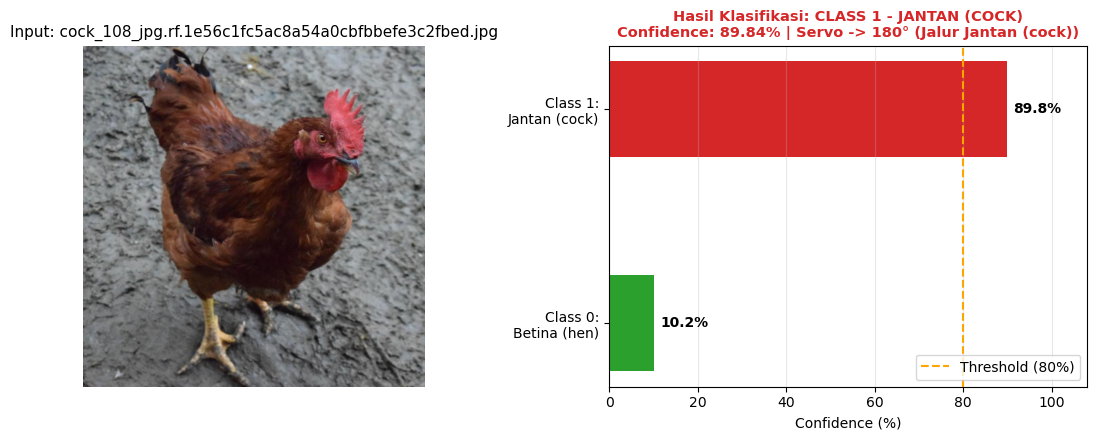

File Gambar       : cock_108_jpg.rf.1e56c1fc5ac8a54a0cbfbbefe3c2fbed.jpg
Hasil Klasifikasi : 1 (Jantan (cock))
Confidence        : 89.84% (Class 0: 10.16% | Class 1: 89.84%)
Aksi ESP32        : Servo -> 180° (Jalur Jantan (cock))
Waktu Inferensi   : 2.58 ms

>>> 2. Menguji Sampel Gambar Jantan (Ekspektasi: Class 1):


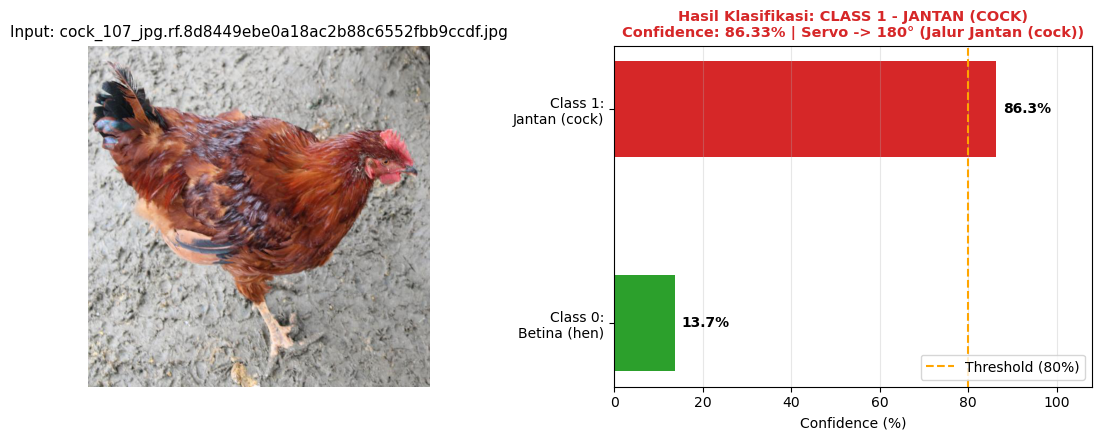

File Gambar       : cock_107_jpg.rf.8d8449ebe0a18ac2b88c6552fbb9ccdf.jpg
Hasil Klasifikasi : 1 (Jantan (cock))
Confidence        : 86.33% (Class 0: 13.67% | Class 1: 86.33%)
Aksi ESP32        : Servo -> 180° (Jalur Jantan (cock))
Waktu Inferensi   : 3.70 ms

>>> 3. Menguji Gambar Kosong / Tanpa Objek Ayam (Ekspektasi: undefined):


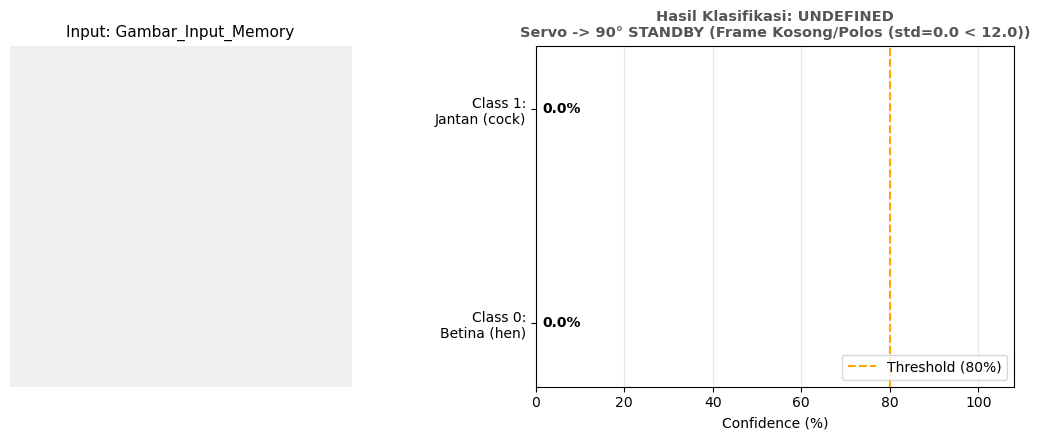

File Gambar       : Gambar_Input_Memory
Hasil Klasifikasi : undefined (undefined (Bukan Ayam / Kosong))
Alasan Undefined  : Frame Kosong/Polos (std=0.0 < 12.0)
Aksi ESP32        : Servo -> 90° STANDBY (Frame Kosong/Polos (std=0.0 < 12.0))
Waktu Inferensi   : 1.71 ms


In [3]:
# Masukkan path gambar Anda di sini, contoh:
# IMAGE_PATH = "../data/Sexing-Chicken-2/test/cock/nama_file.jpg"
IMAGE_PATH = None

if IMAGE_PATH is not None:
    detect_chicken_sex(IMAGE_PATH)
else:
    test_hen_dir = pathlib.Path("../data/Sexing-Chicken-2/test/hen")
    test_cock_dir = pathlib.Path("../data/Sexing-Chicken-2/test/cock")
    if not test_hen_dir.exists():
        test_hen_dir = pathlib.Path("../data/dateset/hen")
        test_cock_dir = pathlib.Path("../data/dateset/cock")

    sample_hen = sorted(list(test_hen_dir.glob("*.jpg")))[0]
    sample_cock = sorted(list(test_cock_dir.glob("*.jpg")))[0]

    print(">>> 1. Menguji Sampel Gambar Betina (Ekspektasi: Class 0):")
    detect_chicken_sex(sample_hen)

    print("\n>>> 2. Menguji Sampel Gambar Jantan (Ekspektasi: Class 1):")
    detect_chicken_sex(sample_cock)

    print("\n>>> 3. Menguji Gambar Kosong / Tanpa Objek Ayam (Ekspektasi: undefined):")
    blank_img = Image.fromarray(np.full((160, 160, 3), 240, dtype=np.uint8))
    detect_chicken_sex(blank_img)

## Langkah 4: Pengujian Grid (Batch Beberapa Gambar Sekaligus)

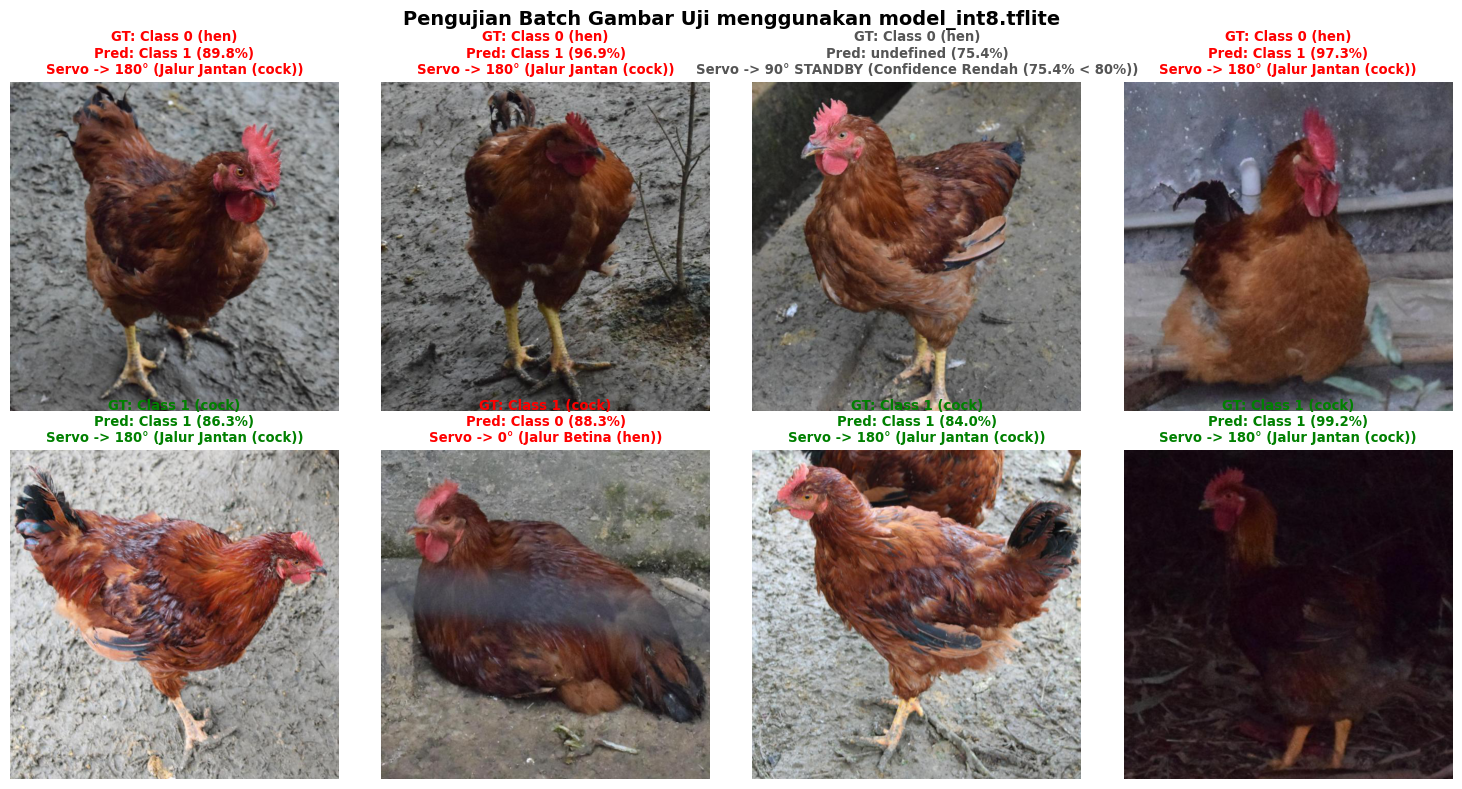

In [4]:
test_hen_files = sorted(list(test_hen_dir.glob("*.jpg")))[:4]
test_cock_files = sorted(list(test_cock_dir.glob("*.jpg")))[:4]
batch_files = test_hen_files + test_cock_files

plt.figure(figsize=(15, 8))
for idx, img_file in enumerate(batch_files):
    res = detect_chicken_sex(img_file, show_plot=False)
    true_cls = 0 if "hen" in img_file.parent.name.lower() else 1
    pred_cls = res["predicted_class"]

    if pred_cls == "undefined":
        title_color = "#555555"
        pred_str = f"Pred: undefined ({res['confidence']*100:.1f}%)"
    else:
        is_correct = pred_cls == true_cls
        title_color = "green" if is_correct else "red"
        pred_str = f"Pred: Class {pred_cls} ({res['confidence']*100:.1f}%)"

    ax = plt.subplot(2, 4, idx + 1)
    ax.imshow(Image.open(img_file).convert("RGB"))
    ax.set_title(
        f"GT: Class {true_cls} ({img_file.parent.name})\n"
        f"{pred_str}\n"
        f"{res['servo_status']}",
        color=title_color,
        fontsize=9.5,
        fontweight="bold",
    )
    ax.axis("off")

plt.suptitle("Pengujian Batch Gambar Uji menggunakan model_int8.tflite", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()